# VO2max representations: unified reproducible analysis
Single source for all tables and figures of the manuscript.

Data: PhysioNet *Treadmill Maximal Exercise Tests*, v1.0.1 (https://doi.org/10.13026/7ezk-j442). Place `subject-info.csv` and `test_measure.csv` next to this notebook.

Two configurations are computed:
* **PUBLISHED**: reproduces the manuscript as drafted (Summary with 24 columns, random `KFold`, Jurca as drafted).
* **CORRECTED**: Summary with 12 distinct variables, `GroupKFold` by participant, cluster bootstrap by participant, Jurca with its published coding.

`FINAL` selects the configuration used for the exported tables and figures.

In [1]:
FINAL='CORRECTED'   # 'PUBLISHED' or 'CORRECTED'
SEED=42; DPI=600; N_BOOT=2000; MET=3.5
import os,sys,warnings,platform,json
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from scipy import stats
import sklearn,xgboost,lightgbm,shap
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression,Lasso
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold,GroupKFold,cross_val_predict
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')
os.makedirs('tables',exist_ok=True); os.makedirs('figures',exist_ok=True)
print(platform.python_version(),'sklearn',sklearn.__version__,'xgboost',xgboost.__version__,'lightgbm',lightgbm.__version__,'shap',shap.__version__)

3.13.18 sklearn 1.9.1 xgboost 3.4.1 lightgbm 4.7.0 shap 0.54.1


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data and study population (Table 3)

In [2]:
su=pd.read_csv('subject-info.csv'); me=pd.read_csv('test_measure.csv').rename(columns={'time':'Time'})
valid=me.groupby('ID_test').VO2.apply(lambda s:s.notna().any()); valid=valid[valid].index
print('tests',su.shape[0],'-> valid',len(valid))
me=me[me.ID_test.isin(valid)].sort_values(['ID_test','Time'])
su=su[su.ID_test.isin(valid)].set_index('ID_test').sort_index()
vo2max=me.groupby('ID_test').VO2.max()
peak=me[me.VO2==me.ID_test.map(vo2max)].groupby('ID_test').head(1).set_index('ID_test')
first=me.groupby('ID_test').head(1).set_index('ID_test')
ix=su.index; y=(vo2max/su.Weight).loc[ix]; yt=y.values; ID=su.ID.values
bmi=su.Weight/(su.Height/100)**2
print('participants',su.ID.nunique(),'with repeated tests',(su.groupby('ID').size()>1).sum())
print('tests <18 y',(su.Age<18).sum(),'participants <18 y',su[su.Age<18].ID.nunique())
d=pd.DataFrame({'Sex':su.Sex.map({0:'Male',1:'Female'}),'Age':su.Age,'VO2max':y,'BMI':bmi})
fmt=lambda s:f'{s.mean():.1f} ± {s.std():.1f}'
t3=d.groupby('Sex').agg(n=('Age','size'),Age=('Age',fmt),VO2max=('VO2max',fmt),BMI=('BMI',fmt)).loc[['Male','Female']]
t3.loc['All']=[len(d),fmt(d.Age),fmt(d.VO2max),fmt(d.BMI)]
t3.to_csv('tables/Table3.csv'); t3

tests 992 -> valid 981
participants 846 with repeated tests 116
tests <18 y 143 participants <18 y 120


,n,Age,VO2max,BMI
Sex,,,,
Male,836,29.5 ± 10.2,50.3 ± 8.8,24.1 ± 2.9
Female,145,26.1 ± 8.7,41.1 ± 6.9,22.4 ± 2.6
All,981,29.0 ± 10.1,48.9 ± 9.1,23.9 ± 2.9


## 2. Representations (Table 4)

In [3]:
STATIC=['Age','Weight','Height','Sex','Humidity','Temperature']
def representations(corrected):
    R={}
    R['Instant_full']=su[['Age','Weight','Height','Humidity','Temperature','Sex']].join(peak[['HR','RR','Speed','VCO2','VE']]).loc[ix]
    o=['HR','RR','Age','Weight','Height','Sex','Humidity','Temperature']
    g=me.groupby('ID_test'); dyn=pd.DataFrame({f'{v}_{s}':getattr(g[v],s)() for v in ['HR','RR'] for s in ['mean','max','std']}).loc[ix]
    if corrected: R['Summary']=dyn.join(su[STATIC])
    else:
        S=dyn.copy()
        for v in ['Age','Weight','Height','Sex','Humidity','Temperature']:
            S[f'{v}_mean']=su[v];S[f'{v}_max']=su[v];S[f'{v}_std']=0.0
        R['Summary']=S[[f'{v}_{s}' for v in o for s in ['mean','max','std']]]
    R['Simple']=su[STATIC].join(peak[['HR','RR']]).loc[ix][o]
    R['Instant0']=su[STATIC].join(first[['HR','RR']]).loc[ix][o]
    return R
REP={'PUBLISHED':representations(False),'CORRECTED':representations(True)}
{k:{r:X.shape[1] for r,X in v.items()} for k,v in REP.items()}

{'PUBLISHED': {'Instant_full': 11, 'Summary': 24, 'Simple': 8, 'Instant0': 8},
 'CORRECTED': {'Instant_full': 11, 'Summary': 12, 'Simple': 8, 'Instant0': 8}}

## 3. Models and out-of-fold evaluation (Table 5)

In [4]:
def models():
    imp=lambda:('imputer',SimpleImputer(strategy='median')); sc=lambda:('scaler',StandardScaler())
    return {'MLR':Pipeline([imp(),sc(),('model',LinearRegression())]),
    'LASSO':Pipeline([imp(),sc(),('model',Lasso(alpha=.001,max_iter=10000,random_state=SEED))]),
    'LightGBM':Pipeline([imp(),('model',LGBMRegressor(n_estimators=200,learning_rate=.05,num_leaves=15,min_data_in_leaf=10,subsample=.8,colsample_bytree=.8,random_state=SEED,verbosity=-1))]),
    'XGBoost':Pipeline([imp(),('model',XGBRegressor(n_estimators=500,learning_rate=.05,max_depth=4,subsample=.8,colsample_bytree=.8,objective='reg:squarederror',random_state=SEED,n_jobs=-1))]),
    'SVR_RBF':Pipeline([imp(),sc(),('model',SVR(kernel='rbf',C=10,epsilon=.1))]),
    'RandomForest':Pipeline([imp(),('model',RandomForestRegressor(n_estimators=300,random_state=SEED,n_jobs=-1))]),
    'KNN':Pipeline([imp(),sc(),('model',KNeighborsRegressor(n_neighbors=7,weights='distance'))])}
def cvfor(cfg): return GroupKFold(5,shuffle=True,random_state=SEED) if cfg=='CORRECTED' else KFold(5,shuffle=True,random_state=SEED)
def wilson(k,n,z=1.959963984540054):
    p=k/n;dn=1+z*z/n;c=(p+z*z/(2*n))/dn;h=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/dn;return 100*(c-h),100*(c+h)
def evaluate(cfg):
    rows=[];oof={}
    for r,X in REP[cfg].items():
        for m,est in models().items():
            p=cross_val_predict(est,X,yt,cv=cvfor(cfg),groups=ID if cfg=='CORRECTED' else None)
            k=int((np.abs(p-yt)<=MET).sum());lo,hi=wilson(k,len(yt));oof[r,m]=p
            rows.append({'Representation':r,'Model':m,'R2':r2_score(yt,p),'RMSE':np.sqrt(mean_squared_error(yt,p)),'Within_1MET':100*k/len(yt),'CI_low':lo,'CI_high':hi})
    return pd.DataFrame(rows),oof
RES={};OOF={}
for c in REP: RES[c],OOF[c]=evaluate(c); RES[c].round(3).to_csv(f'tables/Table5_{c}.csv',index=False)
RES[FINAL].round(3)

,Representation,Model,R2,RMSE,Within_1MET,CI_low,CI_high
0,Instant_full,MLR,0.748,4.578,57.390,54.273,60.450
1,Instant_full,LASSO,0.748,4.578,57.390,54.273,60.450
2,Instant_full,LightGBM,0.735,4.694,59.429,56.325,62.459
3,Instant_full,XGBoost,0.745,4.602,60.652,57.560,63.662
4,Instant_full,SVR_RBF,0.732,4.721,58.919,55.812,61.958
5,Instant_full,RandomForest,0.718,4.839,57.492,54.376,60.551
6,Instant_full,KNN,0.602,5.750,47.197,44.090,50.326
7,Summary,MLR,0.398,7.072,38.736,35.737,41.823
8,Summary,LASSO,0.398,7.072,38.736,35.737,41.823
9,Summary,LightGBM,0.415,6.968,39.246,36.238,42.338


## 4. Uncertainty, Bland-Altman and adult-only sensitivity analysis

In [5]:
def bestmodels(cfg):
    T=RES[cfg]; return T.loc[T.groupby('Representation').R2.idxmax()].set_index('Representation').Model.to_dict()
def boot(cfg,a,b=None):
    rng=np.random.RandomState(SEED); v=[]
    if cfg=='CORRECTED':
        u=np.unique(ID); w={g:np.where(ID==g)[0] for g in u}
        draw=lambda:np.concatenate([w[g] for g in rng.choice(u,len(u))])
    else: draw=lambda:rng.randint(0,len(yt),len(yt))
    for _ in range(N_BOOT):
        i=draw(); s=r2_score(yt[i],a[i]); v.append(s if b is None else s-r2_score(yt[i],b[i]))
    return np.percentile(v,[2.5,97.5])
SUMM={}
for c in REP:
    B=bestmodels(c); O=OOF[c]; S={'best':B}
    S['R2_CI']={r:[r2_score(yt,O[r,m])]+list(boot(c,O[r,m])) for r,m in B.items()}
    a,b=O['Simple',B['Simple']],O['Instant0',B['Instant0']]
    S['Simple_minus_Instant0']=[r2_score(yt,a)-r2_score(yt,b)]+list(boot(c,a,b))
    S['BA']={}
    for r in ['Instant_full','Simple']:
        e=O[r,B[r]]-yt; l=stats.linregress(yt,e); S['BA'][r]=dict(bias=e.mean(),loa=1.96*e.std(ddof=1),slope=l.slope,p=l.pvalue)
    ad=(su.Age>=18).values; S['adults']={}
    for r,m in B.items():
        X=REP[c][r][ad]; p=cross_val_predict(models()[m],X,yt[ad],cv=cvfor(c),groups=ID[ad] if c=='CORRECTED' else None); S['adults'][r]=r2_score(yt[ad],p)
    S['in_sample_within']=100*np.mean(np.abs(models()[B['Instant_full']].fit(REP[c]['Instant_full'],yt).predict(REP[c]['Instant_full'])-yt)<=MET)
    S['in_sample_within_XGB']=100*np.mean(np.abs(models()['XGBoost'].fit(REP[c]['Instant_full'],yt).predict(REP[c]['Instant_full'])-yt)<=MET)
    SUMM[c]=S
json.dump(SUMM,open('tables/summary_stats.json','w'),indent=1,default=float); print(json.dumps(SUMM,indent=1,default=lambda x:round(float(x),4)))

{
 "PUBLISHED": {
  "best": {
   "Instant0": "LASSO",
   "Instant_full": "LASSO",
   "Simple": "LightGBM",
   "Summary": "LightGBM"
  },
  "R2_CI": {
   "Instant0": [
    0.3453762407511535,
    0.2942758922005413,
    0.3910316906157921
   ],
   "Instant_full": [
    0.747176717262598,
    0.714810981177322,
    0.7748432778165334
   ],
   "Simple": [
    0.4097167340071438,
    0.3562992163691391,
    0.4576527103037541
   ],
   "Summary": [
    0.4255933518713737,
    0.37341553002504313,
    0.4730832406910766
   ]
  },
  "Simple_minus_Instant0": [
   0.06434049325599034,
   0.022343295106016237,
   0.10514094365193706
  ],
  "BA": {
   "Instant_full": {
    "bias": -0.0032327438255843922,
    "loa": 8.984040738954658,
    "slope": -0.24775193961430733,
    "p": 3.899237823873871e-61
   },
   "Simple": {
    "bias": 0.03570973951861562,
    "loa": 13.72738685383739,
    "slope": -0.5646449462445249,
    "p": 2.498705631907038e-167
   }
  },
  "adults": {
   "Instant0": 0.3251044545

## 5. PCA of the predictor space (Table 6)

In [6]:
def pca_table(cfg):
    rows=[];P={}
    for r,X in REP[cfg].items():
        Z=StandardScaler().fit_transform(X.fillna(X.median())); p=PCA().fit(Z); v=p.explained_variance_ratio_; c=v.cumsum(); P[r]=(c,pd.DataFrame(p.components_.T,index=X.columns))
        rows.append({'Representation':r,'Vars':X.shape[1],'PC1':100*v[0],'PC2':100*v[1],'PC3':100*v[2],'PCs70':int((c<.7).sum()+1),'PCs80':int((c<.8).sum()+1),'PCs90':int((c<.9).sum()+1)})
    return pd.DataFrame(rows),P
PCAT={};PCAP={}
for c in REP: PCAT[c],PCAP[c]=pca_table(c); PCAT[c].round(1).to_csv(f'tables/Table6_{c}.csv',index=False)
for c in REP: print(c); print(PCAT[c].round(1).to_string(index=False))
for r in ['Instant_full','Summary','Simple','Instant0']: print(r,'PC1 top:',PCAP[FINAL][r][1][0].abs().sort_values(ascending=False).head(3).index.tolist())

PUBLISHED
Representation  Vars  PC1  PC2  PC3  PCs70  PCs80  PCs90
  Instant_full    11 31.2 16.7 10.6      5      6      8
       Summary    24 23.3 19.4 12.6      5      6      8
        Simple     8 25.3 20.3 14.0      4      5      6
      Instant0     8 26.2 16.3 13.8      5      6      7
CORRECTED
Representation  Vars  PC1  PC2  PC3  PCs70  PCs80  PCs90
  Instant_full    11 31.2 16.7 10.6      5      6      8
       Summary    12 25.0 17.5 14.6      5      6      8
        Simple     8 25.3 20.3 14.0      4      5      6
      Instant0     8 26.2 16.3 13.8      5      6      7
Instant_full PC1 top: ['VE', 'VCO2', 'Height']
Summary PC1 top: ['RR_max', 'RR_mean', 'Age']
Simple PC1 top: ['Weight', 'Height', 'Sex']
Instant0 PC1 top: ['Weight', 'Height', 'Sex']


## 6. Classical equations (Table 7)
First-instant HR is used as the proxy for resting HR. PA is absent from the dataset and imputed to the top of each scale. Dataset coding: Sex = 0 male, 1 female.

In [7]:
hr0=first.HR.loc[ix]; male=(1-su.Sex)
def eqs(cfg):
    jur=2.77*(male if cfg=='CORRECTED' else su.Sex); pa_j=3.03 if cfg=='CORRECTED' else 7
    return {'Jackson et al. (1990)':56.363+1.921*7-.381*su.Age-.754*bmi+10.987*male,
      'Jurca et al. (2005)':3.5*(18.07+jur-.10*su.Age-.17*bmi-.03*hr0+pa_j),
      'Jalili et al. (2023)':62.914+.875*su.Age-1.156*bmi-.12*hr0,
      'Rexhepi & Brestovci (2014)':(3.542-.014*su.Age+.015*su.Weight-.011*hr0)*1000/su.Weight}
def t7(cfg):
    rows=[]
    for n,p in eqs(cfg).items():
        k=p.notna();e=p[k]-y[k];rows.append({'Method':n,'n':int(k.sum()),'R2':r2_score(y[k],p[k]),'RMSE':np.sqrt((e**2).mean()),'Bias':e.mean(),'LoA_low':e.mean()-1.96*e.std(ddof=1),'LoA_high':e.mean()+1.96*e.std(ddof=1),'Within_1MET':100*(e.abs()<=MET).mean()})
    B=bestmodels(cfg)
    for r,m in [('Instant_full',B['Instant_full']),('Simple',B['Simple'])]:
        e=OOF[cfg][r,m]-yt;rows.append({'Method':f'{r} - {m} (this study)','n':len(yt),'R2':r2_score(yt,OOF[cfg][r,m]),'RMSE':np.sqrt((e**2).mean()),'Bias':e.mean(),'LoA_low':e.mean()-1.96*e.std(ddof=1),'LoA_high':e.mean()+1.96*e.std(ddof=1),'Within_1MET':100*(np.abs(e)<=MET).mean()})
    return pd.DataFrame(rows)
T7={c:t7(c) for c in REP}
for c in REP: T7[c].round(3).to_csv(f'tables/Table7_{c}.csv',index=False); print(c); print(T7[c].round(3).to_string(index=False))

PUBLISHED
                           Method   n     R2   RMSE   Bias  LoA_low  LoA_high  Within_1MET
            Jackson et al. (1990) 981  0.211  8.091  1.210  -14.478    16.898       35.270
              Jurca et al. (2005) 738 -0.838 12.817  6.740  -14.642    28.122       24.526
             Jalili et al. (2023) 738 -0.833 12.797  0.014  -25.086    25.114       21.409
       Rexhepi & Brestovci (2014) 738 -0.183 10.282 -3.792  -22.537    14.954       24.390
Instant_full - LASSO (this study) 981  0.747  4.581 -0.003   -8.987     8.981       57.187
   Simple - LightGBM (this study) 981  0.410  7.000  0.036  -13.692    13.763       39.144
CORRECTED
                         Method   n     R2   RMSE   Bias  LoA_low  LoA_high  Within_1MET
          Jackson et al. (1990) 981  0.211  8.091  1.210  -14.478    16.898       35.270
            Jurca et al. (2005) 738  0.269  8.084 -0.324  -16.165    15.518       35.637
           Jalili et al. (2023) 738 -0.833 12.797  0.014  -25.086    25.114 

## 7. Interpretability

In [8]:
LAB={'VCO2':'VCO₂'}
def importance(rep,cfg=FINAL):
    X=REP[cfg][rep]; idx=np.arange(len(X)); est=models()['MLR']
    pi=np.zeros(X.shape[1]); sh=np.zeros(X.shape[1]); sg=np.zeros(X.shape[1]); n=0
    cv=cvfor(cfg)
    for tr,te in cv.split(X,yt,groups=ID if cfg=='CORRECTED' else None):
        m=models()['MLR'].fit(X.iloc[tr],yt[tr]); r=permutation_importance(m,X.iloc[te],yt[te],scoring='r2',n_repeats=30,random_state=SEED,n_jobs=-1); pi+=r.importances_mean
        Xt=m[:-1].transform(X.iloc[tr]); Xe=m[:-1].transform(X.iloc[te]); s=shap.LinearExplainer(m[-1],Xt).shap_values(Xe)
        sh+=np.abs(s).mean(0); sg+=m[-1].coef_; n+=1
    return pd.DataFrame({'perm':pi/n,'shap':sh/n,'sign':sg/n},index=X.columns)
IMP={r:importance(r) for r in ['Instant_full','Instant0']}
for r,v in IMP.items(): v.round(3).to_csv(f'tables/Importance_{r}.csv'); print(r); print(v.sort_values('shap',ascending=False).round(3))

Background dataset has 788 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=788 when initializing the masker.


Background dataset has 779 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=779 when initializing the masker.


Background dataset has 781 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=781 when initializing the masker.


Background dataset has 793 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=793 when initializing the masker.


Background dataset has 783 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=783 when initializing the masker.


Background dataset has 788 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=788 when initializing the masker.


Background dataset has 779 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=779 when initializing the masker.


Background dataset has 781 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=781 when initializing the masker.


Background dataset has 793 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=793 when initializing the masker.


Background dataset has 783 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=783 when initializing the masker.


Instant_full
              perm   shap   sign
VCO2         1.092  5.374  6.764
Weight       1.057  5.045 -6.583
Sex          0.039  0.934 -1.291
Age          0.014  0.647 -0.782
Speed        0.015  0.582  0.772
VE           0.011  0.561  0.700
Height       0.009  0.490  0.616
Temperature  0.007  0.441  0.563
HR           0.004  0.343 -0.467
Humidity     0.002  0.230  0.279
RR          -0.000  0.076  0.097
Instant0
              perm   shap   sign
Weight       0.699  4.088 -5.330
Sex          0.415  3.003 -4.160
Height       0.147  2.014  2.542
Age          0.025  0.891 -1.076
HR           0.019  0.625 -0.889
Humidity     0.009  0.494 -0.606
RR          -0.001  0.249  0.341
Temperature -0.001  0.079 -0.052


## 8. Figures (600 dpi)

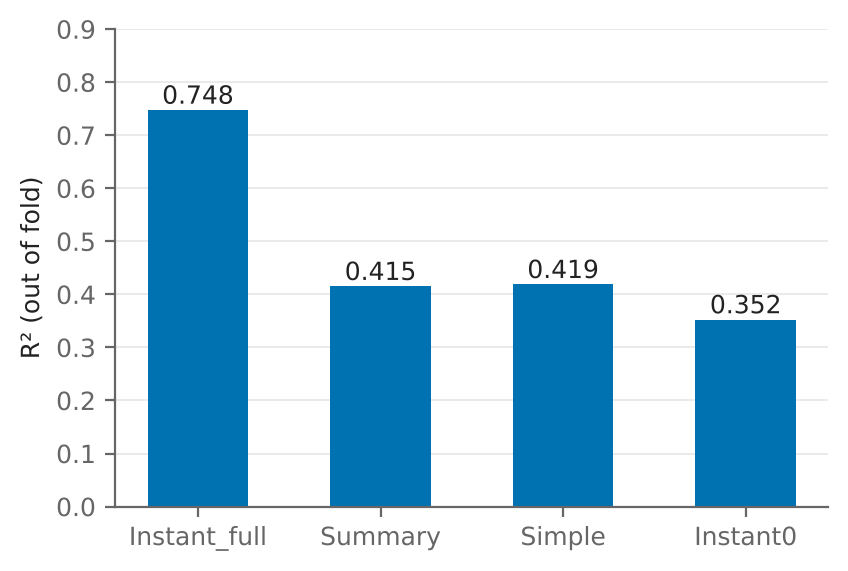

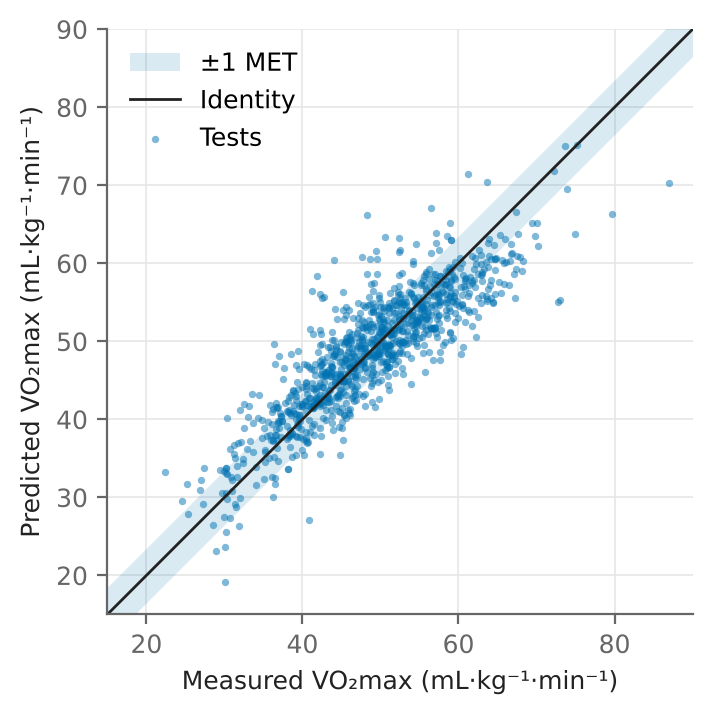

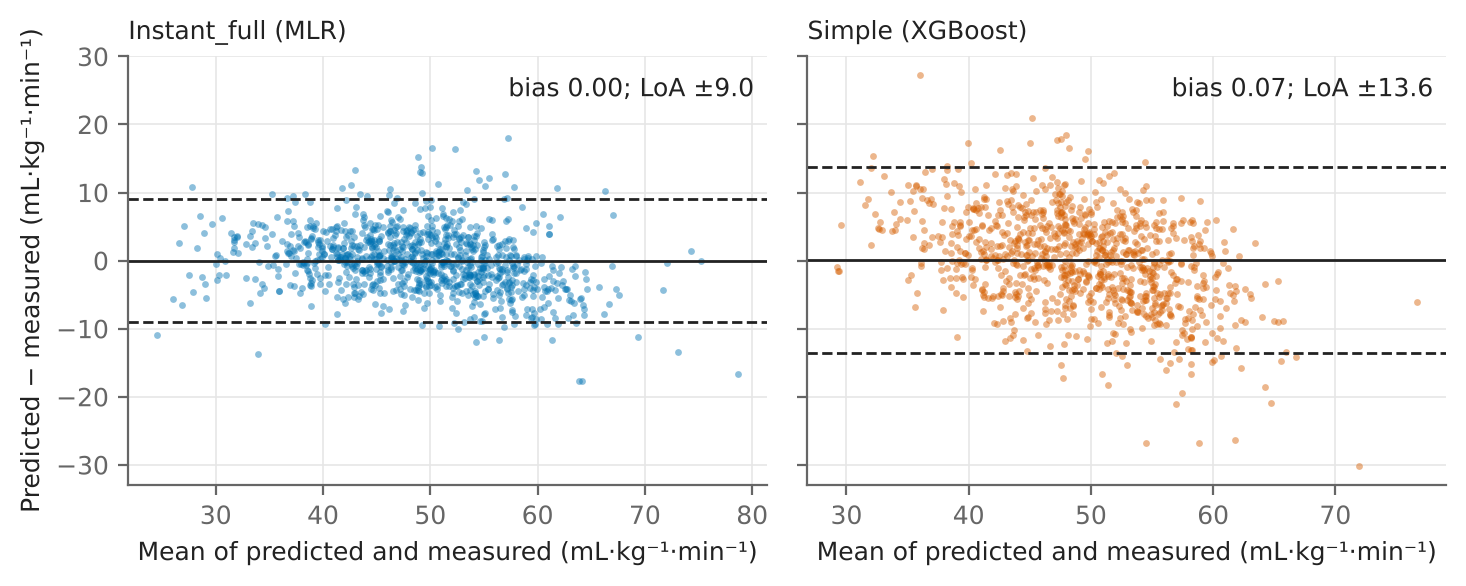

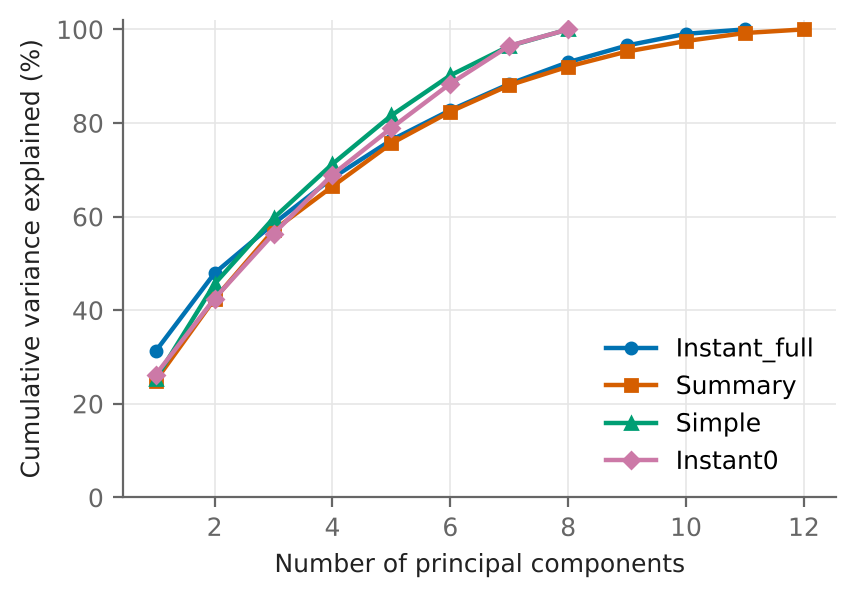

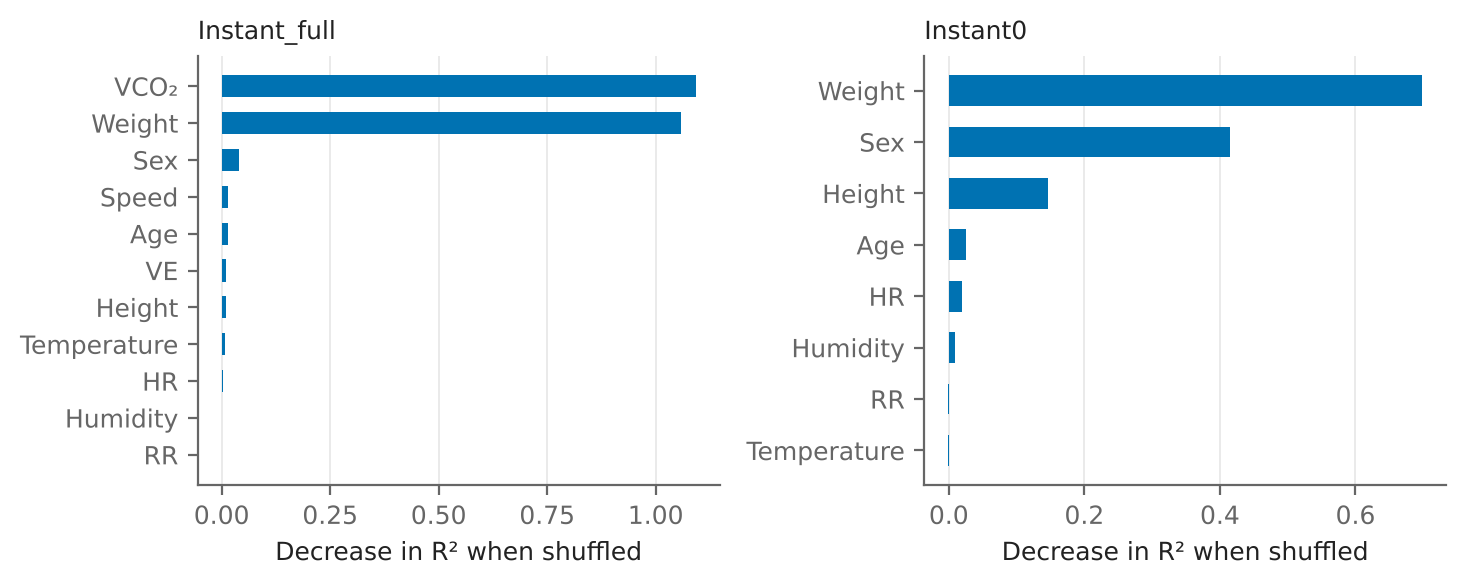

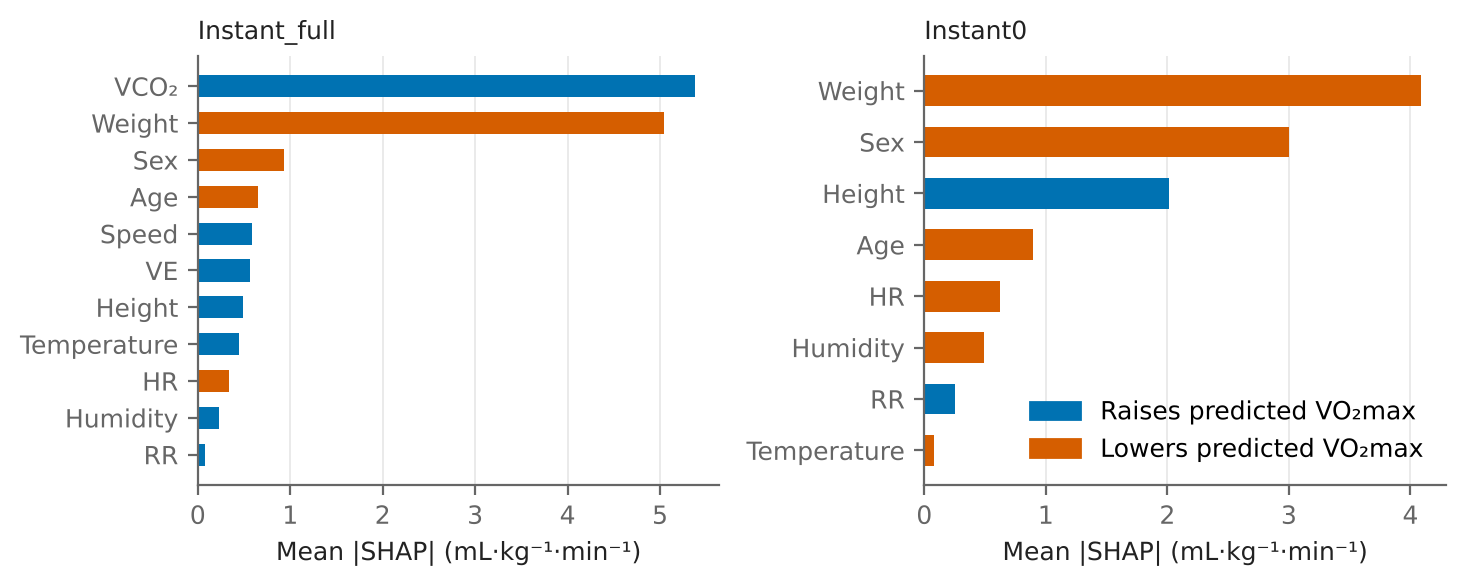

In [9]:
C1,C2,C3,C4,INK,MUTE,GRID='#0072B2','#D55E00','#009E73','#CC79A7','#222222','#666666','#E6E6E6'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':MUTE,'axes.labelcolor':INK,'xtick.color':MUTE,'ytick.color':MUTE,'axes.grid':True,'grid.color':GRID,'grid.linewidth':.6,'axes.axisbelow':True,'legend.frameon':False})
U='mL·kg⁻¹·min⁻¹'; RO=['Instant_full','Summary','Simple','Instant0']; B=bestmodels(FINAL); O=OOF[FINAL]
def save(f,n): f.savefig(f'figures/{n}.png',dpi=DPI,bbox_inches='tight',facecolor='white'); plt.show()
f,a=plt.subplots(figsize=(4.6,3.1)); v=[r2_score(yt,O[r,B[r]]) for r in RO]; b=a.bar(RO,v,color=C1,width=.55)
for x,val in zip(b,v): a.text(x.get_x()+x.get_width()/2,val+.012,f'{val:.3f}',ha='center',color=INK)
a.set_ylabel('R² (out of fold)'); a.set_ylim(0,.9); a.grid(axis='x',visible=False); save(f,'Figure1')
p=O['Instant_full',B['Instant_full']]; f,a=plt.subplots(figsize=(3.8,3.8)); L=[15,90]; xx=np.array(L)
a.fill_between(xx,xx-MET,xx+MET,color=C1,alpha=.15,lw=0,label='±1 MET'); a.plot(xx,xx,color=INK,lw=1,label='Identity'); a.scatter(yt,p,s=7,color=C1,alpha=.5,lw=0,label='Tests')
a.set(xlim=L,ylim=L,xlabel=f'Measured VO₂max ({U})',ylabel=f'Predicted VO₂max ({U})',aspect='equal'); a.legend(loc='upper left'); save(f,'Figure2')
f,ax=plt.subplots(1,2,figsize=(7.4,3),sharey=True)
for a,r,c in zip(ax,['Instant_full','Simple'],[C1,C2]):
    q=O[r,B[r]];e=q-yt;m=e.mean();s=1.96*e.std(ddof=1); a.scatter((q+yt)/2,e,s=6,color=c,alpha=.45,lw=0); a.axhline(m,color=INK,lw=1); a.axhline(m+s,color=INK,lw=1,ls='--'); a.axhline(m-s,color=INK,lw=1,ls='--')
    a.set_title(f'{r} ({B[r]})',fontsize=9,color=INK,loc='left'); a.set_xlabel(f'Mean of predicted and measured ({U})'); a.text(.98,.95,f'bias {m:.2f}; LoA ±{s:.1f}',transform=a.transAxes,ha='right',va='top',color=INK)
ax[0].set_ylabel(f'Predicted − measured ({U})'); f.tight_layout(); save(f,'Figure3')
f,a=plt.subplots(figsize=(4.6,3.1))
for r,c,mk in zip(RO,[C1,C2,C3,C4],['o','s','^','D']):
    cc=PCAP[FINAL][r][0]; a.plot(range(1,len(cc)+1),100*cc,color=c,marker=mk,ms=4,lw=1.6,label=r)
a.set(xlabel='Number of principal components',ylabel='Cumulative variance explained (%)',ylim=(0,102)); a.legend(loc='lower right'); save(f,'Figure4')
nm=lambda s:[LAB.get(i,i) for i in s]
f,ax=plt.subplots(1,2,figsize=(7.4,3))
for a,r in zip(ax,['Instant_full','Instant0']):
    t=IMP[r].sort_values('perm'); a.barh(nm(t.index),t.perm,color=C1,height=.6); a.set_title(r,fontsize=9,color=INK,loc='left'); a.set_xlabel('Decrease in R² when shuffled'); a.grid(axis='y',visible=False)
f.tight_layout(); save(f,'Figure5')
from matplotlib.patches import Patch
f,ax=plt.subplots(1,2,figsize=(7.4,3))
for a,r in zip(ax,['Instant_full','Instant0']):
    t=IMP[r].sort_values('shap'); a.barh(nm(t.index),t.shap,color=[C1 if s>0 else C2 for s in t.sign],height=.6); a.set_title(r,fontsize=9,color=INK,loc='left'); a.set_xlabel(f'Mean |SHAP| ({U})'); a.grid(axis='y',visible=False)
ax[1].legend(handles=[Patch(color=C1,label='Raises predicted VO₂max'),Patch(color=C2,label='Lowers predicted VO₂max')],loc='lower right'); f.tight_layout(); save(f,'Figure6')

## 9. Manuscript vs this notebook

In [10]:
PUB={('Instant_full','MLR'):(.747,4.58,57.2),('Instant_full','XGBoost'):(.74,4.64,60.9),('Instant_full','LightGBM'):(.741,4.64,60.1),('Instant_full','RandomForest'):(.718,4.84,58.2),('Instant_full','SVR_RBF'):(.733,4.71,59.6),('Instant_full','KNN'):(.593,5.81,46.4),('Instant_full','LASSO'):(.747,4.58,57.2),
('Summary','LightGBM'):(.426,6.91,39.7),('Summary','XGBoost'):(.425,6.91,41.1),('Summary','RandomForest'):(.404,7.03,39.7),('Summary','MLR'):(.394,7.1,39.3),('Summary','LASSO'):(.394,7.1,39.4),('Summary','SVR_RBF'):(.388,7.13,41.0),('Summary','KNN'):(.333,7.44,37.9),
('Simple','LightGBM'):(.41,7.0,39.1),('Simple','XGBoost'):(.403,7.04,38.1),('Simple','SVR_RBF'):(.399,7.06,42.5),('Simple','MLR'):(.387,7.13,39.7),('Simple','LASSO'):(.387,7.13,39.7),('Simple','RandomForest'):(.382,7.16,38.9),('Simple','KNN'):(.304,7.6,36.5),
('Instant0','MLR'):(.345,7.37,40.0),('Instant0','LASSO'):(.345,7.37,39.9),('Instant0','LightGBM'):(.335,7.43,37.5),('Instant0','RandomForest'):(.327,7.47,38.9),('Instant0','SVR_RBF'):(.319,7.52,37.8),('Instant0','XGBoost'):(.315,7.54,37.6),('Instant0','KNN'):(.241,7.94,37.4)}
rows=[]
for (r,m),(a,b,c) in PUB.items():
    x=RES['PUBLISHED'].query('Representation==@r and Model==@m').iloc[0]; z=RES['CORRECTED'].query('Representation==@r and Model==@m').iloc[0]
    rows.append(dict(rep=r,model=m,R2_ms=a,R2_repro=round(x.R2,3),W_ms=c,W_repro=round(x.Within_1MET,1),R2_corr=round(z.R2,3),W_corr=round(z.Within_1MET,1)))
CMP=pd.DataFrame(rows); CMP['dR2']=(CMP.R2_repro-CMP.R2_ms).round(3); CMP['dW']=(CMP.W_repro-CMP.W_ms).round(1); CMP.to_csv('tables/Comparison_Table5.csv',index=False); print(CMP.to_string(index=False)); print('non-XGB max|dR2|',CMP[CMP.model!='XGBoost'].dR2.abs().max(),'max|dW|',CMP[CMP.model!='XGBoost'].dW.abs().max())

         rep        model  R2_ms  R2_repro  W_ms  W_repro  R2_corr  W_corr    dR2   dW
Instant_full          MLR  0.747     0.747  57.2     57.2    0.748    57.4  0.000  0.0
Instant_full      XGBoost  0.740     0.741  60.9     60.3    0.745    60.7  0.001 -0.6
Instant_full     LightGBM  0.741     0.741  60.1     60.1    0.735    59.4  0.000  0.0
Instant_full RandomForest  0.718     0.719  58.2     58.1    0.718    57.5  0.001 -0.1
Instant_full      SVR_RBF  0.733     0.733  59.6     59.6    0.732    58.9  0.000  0.0
Instant_full          KNN  0.593     0.593  46.4     46.4    0.602    47.2  0.000  0.0
Instant_full        LASSO  0.747     0.747  57.2     57.2    0.748    57.4  0.000  0.0
     Summary     LightGBM  0.426     0.426  39.7     39.7    0.415    39.2  0.000  0.0
     Summary      XGBoost  0.425     0.419  41.1     41.2    0.411    39.2 -0.006  0.1
     Summary RandomForest  0.404     0.403  39.7     39.4    0.386    39.2 -0.001 -0.3
     Summary          MLR  0.394     0.394 